<a href="https://colab.research.google.com/github/Junghwan0516/early-learning-support/blob/main/Untitled25.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()

Saving features_day28.csv to features_day28.csv


In [3]:
data_path = Path("features_day28.csv")

df = pd.read_csv(data_path)

print(f"Total records: {df.shape[0]:,}")
print(f"Total columns: {df.shape[1]}")

display(df.head())

Total records: 5,062
Total columns: 12


,code_module,code_presentation,id_student,clicks_w1,clicks_w2,clicks_w3,clicks_w4,active_days,days_since_activity,last_week_change,total_clicks,target
0,BBB,2013B,23629,23.0,5.0,9.0,2.0,5.0,6.0,-7.0,39.0,0
1,BBB,2013B,25107,10.0,0.0,66.0,3.0,5.0,5.0,-63.0,79.0,0
2,BBB,2013B,27891,124.0,18.0,16.0,13.0,7.0,4.0,-3.0,171.0,1
3,BBB,2013B,29144,126.0,0.0,74.0,0.0,9.0,7.0,-74.0,200.0,0
4,BBB,2013B,31663,302.0,97.0,188.0,238.0,27.0,0.0,50.0,825.0,0


In [4]:
train = df.loc[
    df["code_module"].eq("BBB")
    & df["code_presentation"].eq("2013B")
].copy()

feature_columns = [
    "clicks_w1",
    "clicks_w2",
    "clicks_w3",
    "clicks_w4",
    "active_days",
    "days_since_activity",
    "last_week_change",
    "total_clicks",
]

print(f"Training records: {len(train):,}")
print(f"Later withdrawals: {int(train['target'].sum()):,}")
print(f"Withdrawal rate: {train['target'].mean():.2%}")

quality_summary = pd.DataFrame({
    "data_type": train[feature_columns + ["target"]].dtypes,
    "missing_values": train[feature_columns + ["target"]].isna().sum(),
})

display(quality_summary)

duplicate_count = train.duplicated(
    ["code_module", "code_presentation", "id_student"]
).sum()

print(f"Duplicate learner-presentation records: {duplicate_count}")

Training records: 1,522
Later withdrawals: 269
Withdrawal rate: 17.67%


,data_type,missing_values
clicks_w1,float64,0
clicks_w2,float64,0
clicks_w3,float64,0
clicks_w4,float64,0
active_days,float64,0
days_since_activity,float64,0
last_week_change,float64,0
total_clicks,float64,0
target,int64,0


Duplicate learner-presentation records: 0


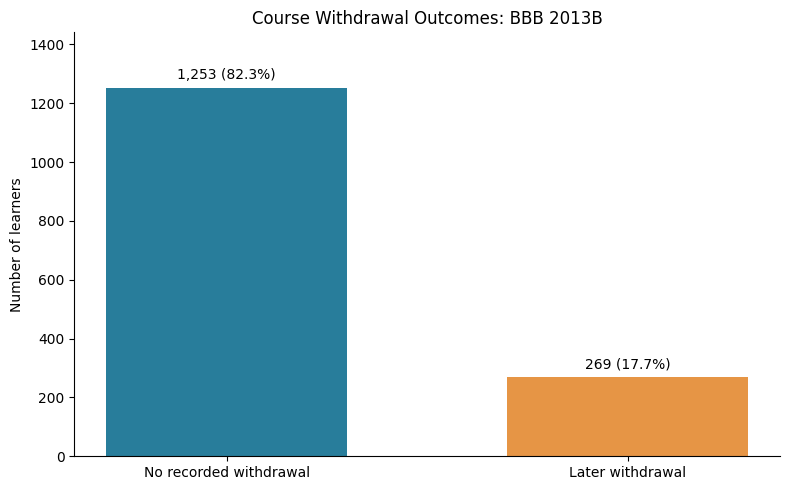

In [5]:
outcome_counts = (
    train["target"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

outcome_labels = [
    "No recorded withdrawal",
    "Later withdrawal",
]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    outcome_labels,
    outcome_counts.values,
    color=["#287D9B", "#E69545"],
    width=0.6,
)

for bar, count in zip(bars, outcome_counts.values):
    percentage = count / len(train) * 100

    ax.annotate(
        f"{count:,} ({percentage:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
    )

ax.set_title("Course Withdrawal Outcomes: BBB 2013B")
ax.set_ylabel("Number of learners")
ax.set_ylim(0, outcome_counts.max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [6]:
majority_class_accuracy = train["target"].eq(0).mean()

print(
    "Accuracy when predicting no withdrawal for every learner: "
    f"{majority_class_accuracy:.2%}"
)
print("Withdrawal recall for this approach: 0.00%")

Accuracy when predicting no withdrawal for every learner: 82.33%
Withdrawal recall for this approach: 0.00%


In [7]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

train = df.loc[
    df["code_module"].eq("BBB")
    & df["code_presentation"].eq("2013B")
].copy()

required_columns = [
    "total_clicks",
    "active_days",
    "days_since_activity",
    "clicks_w1",
    "clicks_w2",
    "clicks_w3",
    "clicks_w4",
    "target",
]

assert not train.empty, "The training cohort is empty."
assert not train[required_columns].isna().any().any(), (
    "Missing values require investigation."
)
assert train["target"].isin([0, 1]).all(), (
    "Unexpected target values."
)

output_dir = Path("figures")
output_dir.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

baseline_rate = train["target"].mean()

print(f"Training records: {len(train):,}")
print(f"Overall withdrawal rate: {baseline_rate:.2%}")

Training records: 1,522
Overall withdrawal rate: 17.67%


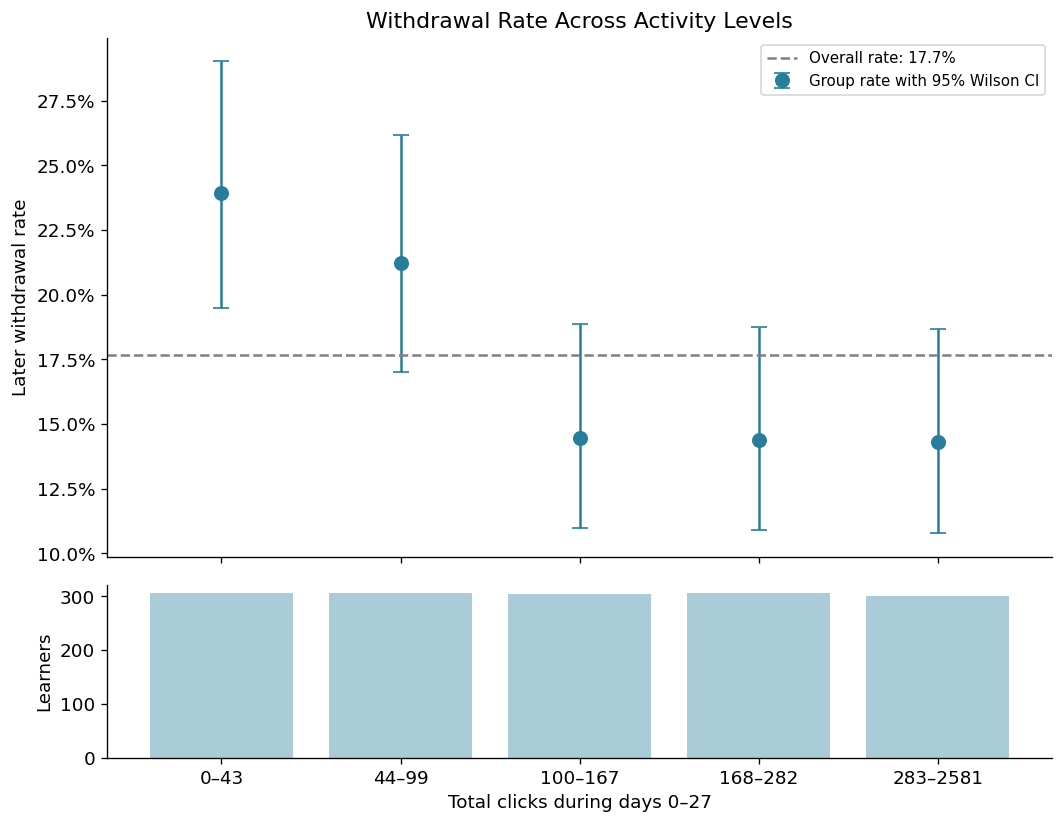

,learners,withdrawals,min_clicks,max_clicks,withdrawal_rate,ci_lower,ci_upper
0,305,73,0.0,43.0,0.239,0.195,0.290
1,306,65,44.0,99.0,0.212,0.170,0.262
2,304,44,100.0,167.0,0.145,0.110,0.189
3,306,44,168.0,282.0,0.144,0.109,0.188
4,301,43,283.0,2581.0,0.143,0.108,0.187


In [8]:
def wilson_interval(successes, totals, z=1.96):
    """Calculate Wilson confidence intervals for binomial proportions."""
    successes = np.asarray(successes, dtype=float)
    totals = np.asarray(totals, dtype=float)

    proportion = successes / totals
    denominator = 1 + z**2 / totals

    center = (
        proportion + z**2 / (2 * totals)
    ) / denominator

    margin = (
        z
        * np.sqrt(
            proportion * (1 - proportion) / totals
            + z**2 / (4 * totals**2)
        )
        / denominator
    )

    return center - margin, center + margin


train["activity_bin"] = pd.qcut(
    train["total_clicks"],
    q=5,
    duplicates="drop",
)

activity_summary = (
    train.groupby("activity_bin", observed=True)
    .agg(
        learners=("target", "size"),
        withdrawals=("target", "sum"),
        min_clicks=("total_clicks", "min"),
        max_clicks=("total_clicks", "max"),
    )
    .reset_index()
)

activity_summary["withdrawal_rate"] = (
    activity_summary["withdrawals"]
    / activity_summary["learners"]
)

lower, upper = wilson_interval(
    activity_summary["withdrawals"],
    activity_summary["learners"],
)

activity_summary["ci_lower"] = lower
activity_summary["ci_upper"] = upper

x = np.arange(len(activity_summary))
rates = activity_summary["withdrawal_rate"].to_numpy()

fig, axes = plt.subplots(
    2, 1,
    figsize=(9, 7),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]},
)

axes[0].errorbar(
    x,
    rates,
    yerr=np.maximum(0, np.vstack([
        rates - lower,
        upper - rates,
    ])),
    fmt="o",
    markersize=8,
    capsize=5,
    color="#287D9B",
    label="Group rate with 95% Wilson CI",
)

axes[0].axhline(
    baseline_rate,
    linestyle="--",
    color="gray",
    label=f"Overall rate: {baseline_rate:.1%}",
)

axes[0].set_title("Withdrawal Rate Across Activity Levels")
axes[0].set_ylabel("Later withdrawal rate")
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(fontsize=9)

axes[1].bar(
    x,
    activity_summary["learners"],
    color="#A9CCD8",
)

axes[1].set_ylabel("Learners")
axes[1].set_xlabel("Total clicks during days 0–27")

labels = [
    f"{row.min_clicks:.0f}–{row.max_clicks:.0f}"
    for row in activity_summary.itertuples()
]

axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)

plt.tight_layout()
fig.savefig(
    output_dir / "01_activity_withdrawal_rate.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

display(activity_summary.drop(columns="activity_bin").round(3))

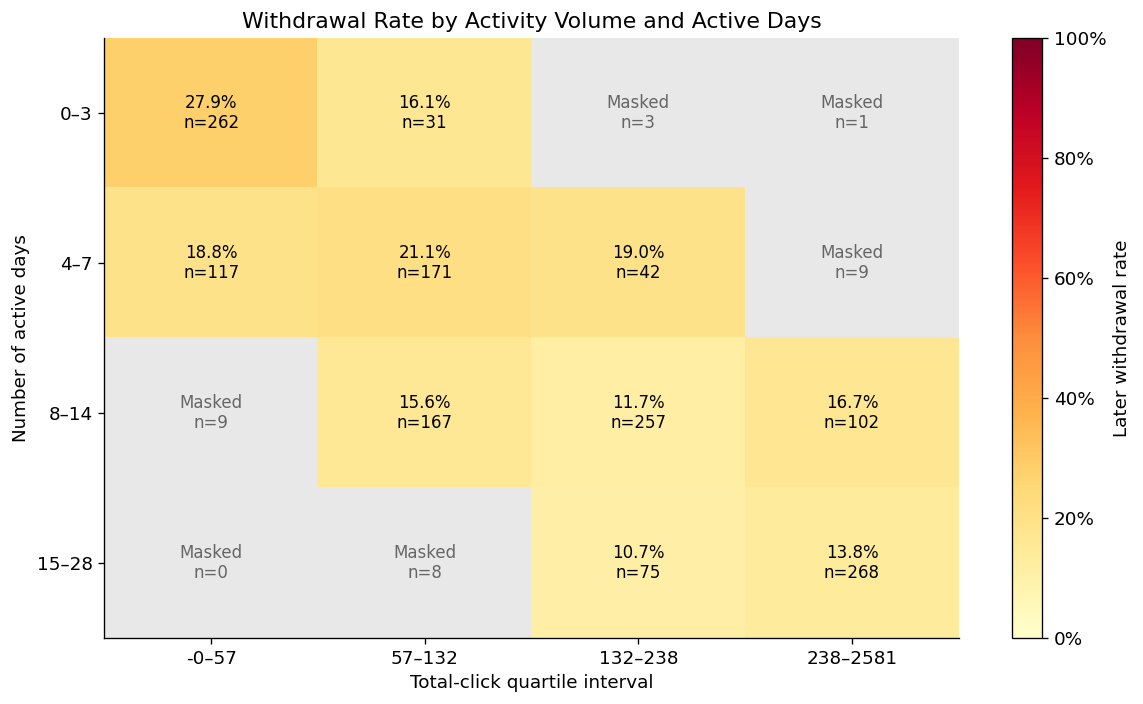

In [9]:
train["volume_group"] = pd.qcut(
    train["total_clicks"],
    q=4,
    duplicates="drop",
)

day_labels = ["0–3", "4–7", "8–14", "15–28"]

train["active_days_group"] = pd.cut(
    train["active_days"],
    bins=[-1, 3, 7, 14, 28],
    labels=day_labels,
)

rates = pd.crosstab(
    train["active_days_group"],
    train["volume_group"],
    values=train["target"],
    aggfunc="mean",
    dropna=False,
)

counts = pd.crosstab(
    train["active_days_group"],
    train["volume_group"],
    dropna=False,
)

volume_order = train["volume_group"].cat.categories

rates = rates.reindex(
    index=day_labels,
    columns=volume_order,
)

counts = counts.reindex(
    index=day_labels,
    columns=volume_order,
    fill_value=0,
)

min_group_size = 20
visible_rates = rates.where(counts >= min_group_size)

color_map = plt.get_cmap("YlOrRd").copy()
color_map.set_bad("#E8E8E8")

fig, ax = plt.subplots(figsize=(10, 6))

image = ax.imshow(
    np.ma.masked_invalid(visible_rates.to_numpy()),
    cmap=color_map,
    vmin=0,
    vmax=1,
    aspect="auto",
)

volume_labels = [
    f"{group.left:.0f}–{group.right:.0f}"
    for group in volume_order
]

ax.set_xticks(np.arange(len(volume_order)))
ax.set_xticklabels(volume_labels)
ax.set_yticks(np.arange(len(day_labels)))
ax.set_yticklabels(day_labels)

for row in range(len(day_labels)):
    for col in range(len(volume_order)):
        n = int(counts.iloc[row, col])
        rate = rates.iloc[row, col]

        if n >= min_group_size and pd.notna(rate):
            text = f"{rate:.1%}\nn={n}"
            color = "white" if rate > 0.55 else "black"
        else:
            text = f"Masked\nn={n}"
            color = "#666666"

        ax.text(
            col, row, text,
            ha="center",
            va="center",
            color=color,
            fontsize=10,
        )

ax.set_title("Withdrawal Rate by Activity Volume and Active Days")
ax.set_xlabel("Total-click quartile interval")
ax.set_ylabel("Number of active days")

colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Later withdrawal rate")
colorbar.ax.yaxis.set_major_formatter(PercentFormatter(1))

plt.tight_layout()
fig.savefig(
    output_dir / "02_volume_consistency_heatmap.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

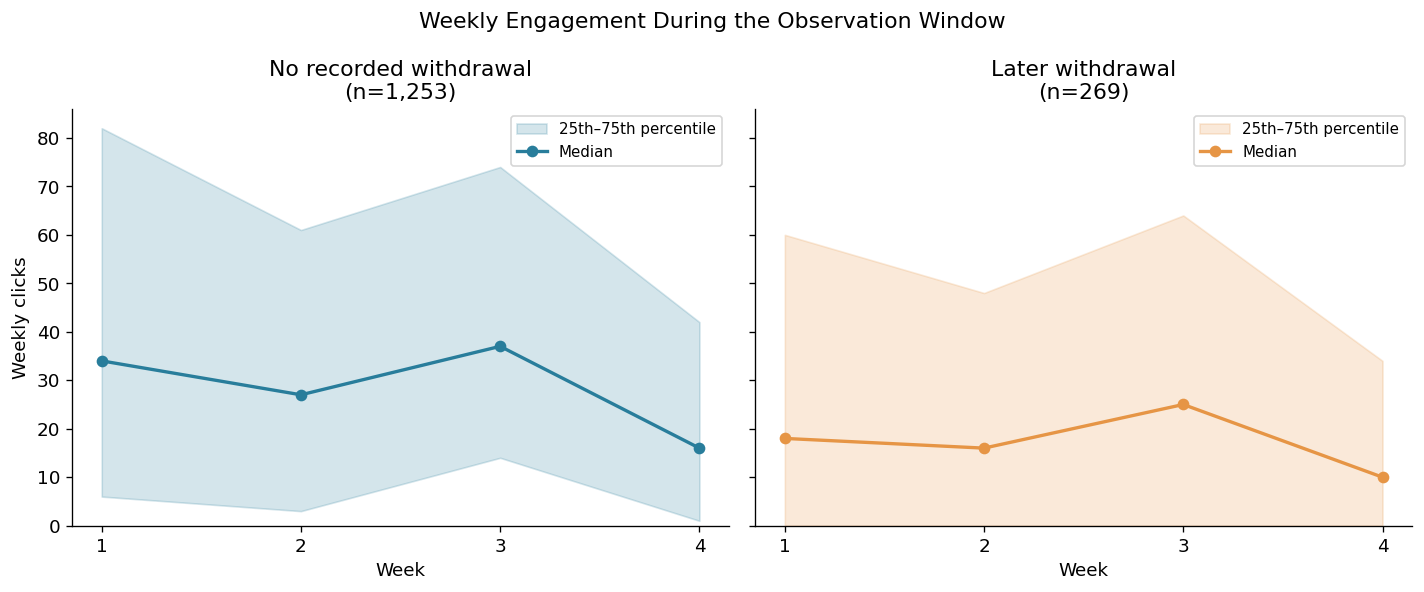

,outcome,week,median_clicks,q25_clicks,q75_clicks
0,No recorded withdrawal,1,34.0,6.0,82.0
1,No recorded withdrawal,2,27.0,3.0,61.0
2,No recorded withdrawal,3,37.0,14.0,74.0
3,No recorded withdrawal,4,16.0,1.0,42.0
4,Later withdrawal,1,18.0,0.0,60.0
5,Later withdrawal,2,16.0,0.0,48.0
6,Later withdrawal,3,25.0,0.0,64.0
7,Later withdrawal,4,10.0,0.0,34.0


In [10]:
weekly_columns = [
    "clicks_w1",
    "clicks_w2",
    "clicks_w3",
    "clicks_w4",
]

weeks = np.arange(1, 5)

groups = [
    (0, "No recorded withdrawal", "#287D9B"),
    (1, "Later withdrawal", "#E69545"),
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharex=True,
    sharey=True,
)

weekly_tables = []

for ax, (target, label, color) in zip(axes, groups):
    subset = train.loc[
        train["target"].eq(target),
        weekly_columns,
    ]

    median = subset.median().to_numpy()
    q25 = subset.quantile(0.25).to_numpy()
    q75 = subset.quantile(0.75).to_numpy()

    ax.fill_between(
        weeks,
        q25,
        q75,
        color=color,
        alpha=0.2,
        label="25th–75th percentile",
    )

    ax.plot(
        weeks,
        median,
        marker="o",
        linewidth=2,
        color=color,
        label="Median",
    )

    ax.set_title(f"{label}\n(n={len(subset):,})")
    ax.set_xlabel("Week")
    ax.set_xticks(weeks)
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=9)

    weekly_tables.append(pd.DataFrame({
        "outcome": label,
        "week": weeks,
        "median_clicks": median,
        "q25_clicks": q25,
        "q75_clicks": q75,
    }))

axes[0].set_ylabel("Weekly clicks")
fig.suptitle("Weekly Engagement During the Observation Window")

plt.tight_layout()
fig.savefig(
    output_dir / "03_weekly_engagement.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

weekly_summary = pd.concat(
    weekly_tables,
    ignore_index=True,
)

display(weekly_summary)